In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import factorial

from pandas.core._numba.kernels import shared

---
## 1. Anscombe's quartet (1973)
Four small datasets of 11 points each.

In [2]:
df = pd.read_csv("https://raw.githubusercontent.com/mwaskom/seaborn-data/master/anscombe.csv")
df

,dataset,x,y
0,I,10.0,8.04
1,I,8.0,6.95
2,I,13.0,7.58
3,I,9.0,8.81
4,I,11.0,8.33
5,I,14.0,9.96
6,I,6.0,7.24
7,I,4.0,4.26
8,I,12.0,10.84
9,I,7.0,4.82


In [3]:
# Code 1: the same summary for each dataset
for name, g in df.groupby("dataset"):
    print(name,
          "x mean", round(g.x.mean(), 2),
          "y mean", round(g.y.mean(), 2),
          "y sd", round(g.y.std(), 2),
          "corr", round(g.x.corr(g.y), 3))

I x mean 9.0 y mean 7.5 y sd 2.03 corr 0.816
II x mean 9.0 y mean 7.5 y sd 2.03 corr 0.816
III x mean 9.0 y mean 7.5 y sd 2.03 corr 0.816
IV x mean 9.0 y mean 7.5 y sd 2.03 corr 0.817


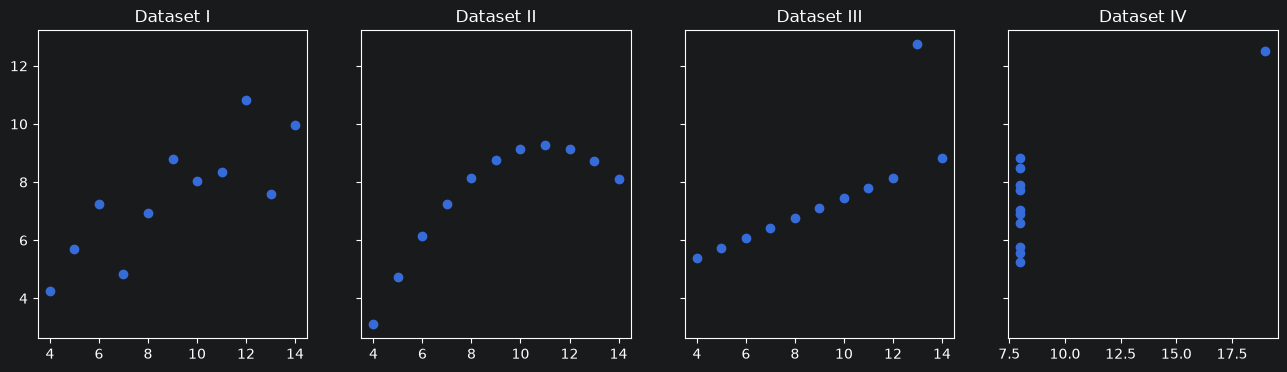

In [4]:

# Subplot
fig, axes = plt.subplots(1, 4, figsize=(16,4), sharey=True)

for ax, (name, g) in zip(axes, df.groupby("dataset")):
    ax.scatter(g.x, g.y)
    ax.set_title("Dataset " + name)
plt.show()

In [6]:
for i in zip(range(1,10)):
    print(i)

(1,)
(2,)
(3,)
(4,)
(5,)
(6,)
(7,)
(8,)
(9,)


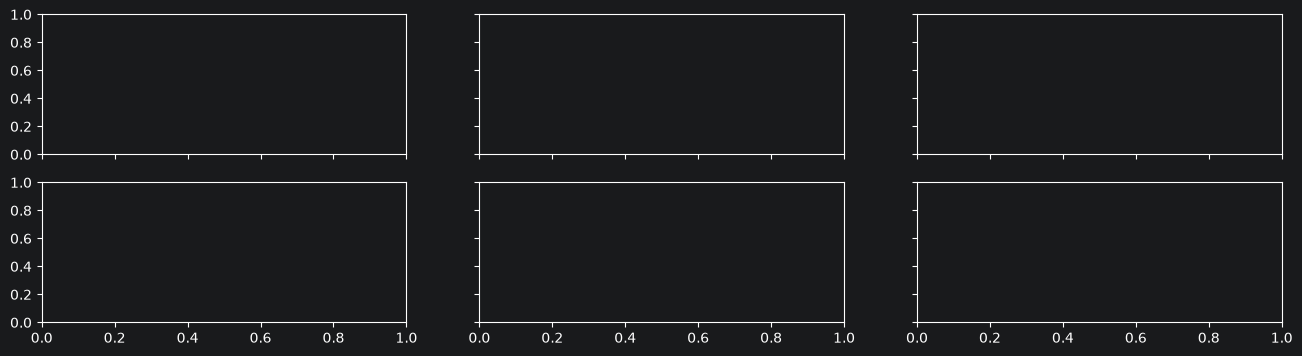

In [27]:
fig, axes = plt.subplots(2, 3, figsize=(16,4), sharex=True, sharey=True)
stores = pd.read_csv('kalpa_store_audit.csv')
groups = list(stores.groupby("store"))
print(zip(axes.flat, groups))


In [33]:
for x in axes.flat:
    print(x)
# print(groups)

Axes(0.125,0.53;0.227941x0.35)
Axes(0.398529,0.53;0.227941x0.35)
Axes(0.672059,0.53;0.227941x0.35)
Axes(0.125,0.11;0.227941x0.35)
Axes(0.398529,0.11;0.227941x0.35)
Axes(0.672059,0.11;0.227941x0.35)
[('S1',    store  distance_km  delivery_min
0     S1         1.06          19.8
1     S1         1.26          19.8
2     S1         1.32          24.2
3     S1         1.54          13.0
4     S1         1.54          16.0
5     S1         1.55          15.2
6     S1         1.59          10.9
7     S1         1.63          20.2
8     S1         1.63          22.1
9     S1         1.90          16.5
10    S1         1.91          27.0
11    S1         1.97          24.4
12    S1         2.06          23.7
13    S1         2.25          23.0
14    S1         2.26          25.8
15    S1         2.63          15.4
16    S1         2.70          25.2
17    S1         3.00          25.9
18    S1         3.17          14.6
19    S1         3.25          25.3
20    S1         3.33          22.5
21

Text(0.02, 0.5, 'Delivery Time (min)')

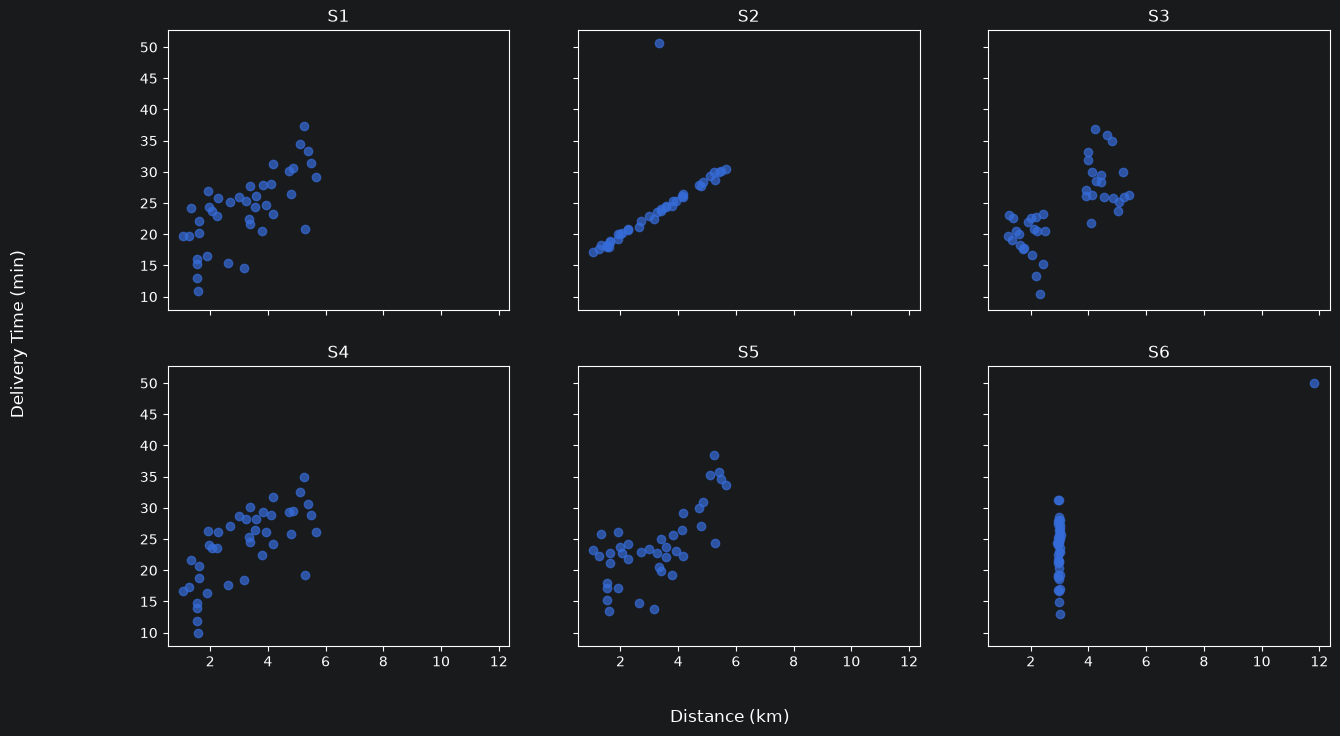

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
stores = pd.read_csv('kalpa_store_audit.csv')
# Convert groupby to a list to check its length
groups = list(stores.groupby("store"))

for ax, (name, g) in zip(axes.flat, groups):
    ax.scatter(g.distance_km, g.delivery_min, alpha=0.7)
    ax.set_title(name)

# Hide any remaining empty subplots
for ax in axes.flat[len(groups):]:
    ax.axis('off')

fig.supxlabel('Distance (km)')
fig.supylabel('Delivery Time (min)')

In [8]:
# Code 3: hire the top 1 percent, then look only at the hires
rng = np.random.default_rng(7)
n = 100_000
contest = rng.normal(0, 1, n)                  # contest skill
job = 0.2 * contest + rng.normal(0, 1, n)      # job skill, mildly related
interview = job + rng.normal(0, 1, n)          # interview sees job skill, noisily
score = 2 * contest + interview                # hiring score leans on contests
hired = score > np.quantile(score, 0.99)       # top 1 percent

print("everyone:", round(np.corrcoef(contest, job)[0, 1], 2))
print("hired   :", round(np.corrcoef(contest[hired], job[hired])[0, 1], 2))

everyone: 0.2
hired   : -0.38


In [9]:
# Code 4: change how much the hiring score leans on contests
for w in [0, 0.5, 1, 2, 4]:
    score = w * contest + interview
    hired = score > np.quantile (score, 0.99)
    r = np.corrcoef (contest [hired], job [hired]) [0, 1]
    print("weight", w, "-> correlation among hires", round(r, 2))

weight 0 -> correlation among hires 0.14
weight 0.5 -> correlation among hires -0.11
weight 1 -> correlation among hires -0.26
weight 2 -> correlation among hires -0.38
weight 4 -> correlation among hires -0.38


---
## Task 2: Kalpa Financial loans (10 marks)

20,000 applicants. Approval rule: credit score 760 or above, **or** income of
15 lakh or more with credit score 650 or above. Default is known only for approved loans.

The risk team says: *"Borrowers earning 15 lakh or more default the most. Tighten income rules."*

1. Correlation of income and credit score: all applicants, then approved only. (2)
2. Default rate by income band, approved only. Bands: under 8, 8 to 12, 12 to 15, 15 and above. (3)
3. Repeat step 2 for approved borrowers with credit score 760 or above only. (3)
4. Write a two-line reply to the risk team. (2)


In [11]:
loans = pd.read_csv("kalpa_loans.csv")
ok = loans[loans.approved == 1].copy()
# TODO 1: correlation of income_lpa and credit_score, all applicants and approved only
print("All applicants :", round(loans.income_lpa.corr(loans.credit_score), 2))
print("Approved only  :", round(ok.income_lpa.corr(ok.credit_score), 2))


All applicants : 0.23
Approved only  : -0.38


In [14]:
ok.head()

,applicant_id,income_lpa,credit_score,approved,defaulted,band
1,2,18.4,689,1,1.0,15+
3,4,20.2,687,1,1.0,15+
8,9,7.1,770,1,0.0,under 8
16,17,26.6,679,1,0.0,15+
17,18,15.6,779,1,0.0,15+


In [12]:
bands = [0, 8, 12, 15, np.inf]
labels = ["under 8", "8-12", "12-15", "15+"]
ok["band"] = pd.cut(ok.income_lpa, bands, labels=labels, right=False)
# TODO 2: default rate (mean of defaulted) and average credit score by band
print("Default rate and average credit score by band:")
display(ok.groupby("band", observed=False)[["defaulted", "credit_score"]].mean())

# TODO 3: the same table for approved borrowers with credit_score >= 760
print("Approved borrowers with credit_score >= 760:")
display(ok[ok.credit_score >= 760].groupby("band", observed=False)[["defaulted", "credit_score"]].mean())


Default rate and average credit score by band:


,defaulted,credit_score
band,,
under 8,0.059211,794.315058
8-12,0.026747,797.827437
12-15,0.011905,799.421769
15+,0.070974,743.704277


Approved borrowers with credit_score >= 760:


,defaulted,credit_score
band,,
under 8,0.059211,794.315058
8-12,0.026747,797.827437
12-15,0.011905,799.421769
15+,0.014925,800.838308


---
## 3. The bullwhip effect: P&G Pampers
A four-tier chain. Each tier forecasts from the orders it receives and orders enough to restore its target stock.

In [13]:
def simulate(demand, lead=2, window=8, share_pos=False, tiers=4):
    orders = [demand]                          # tier 0 is the shopper
    for k in range(tiers):
        incoming = orders[-1]                  # what this tier receives
        signal = demand if share_pos else incoming
        f = pd.Series(signal).rolling(window, min_periods=1).mean().to_numpy()
        target = f * (lead + 1)                # stock to cover lead time
        out = incoming + np.diff(target, prepend=target[0])
        orders.append(np.clip(out, 0, None))   # orders cannot be negative
    return orders

In [15]:
# Code 6: steady demand in, order swings out
rng = np.random.default_rng(7)
demand = rng.normal(100, 10, 104)              # two years of weekly demand
orders = simulate(demand)
names = ["Shoppers", "Retailer", "Distributor", "Manufacturer", "Supplier"]
for name, o in zip(names, orders):
    print(name.ljust(13), "variance ratio", round(o.var() / demand.var(), 1))

shared = simulate(demand, share_pos=True)
print("Supplier with shared sales data:",
      round(shared[-1].var() / demand.var(), 1))

Shoppers      variance ratio 1.0
Retailer      variance ratio 2.0
Distributor   variance ratio 4.6
Manufacturer  variance ratio 11.6
Supplier      variance ratio 31.0
Supplier with shared sales data: 8.3


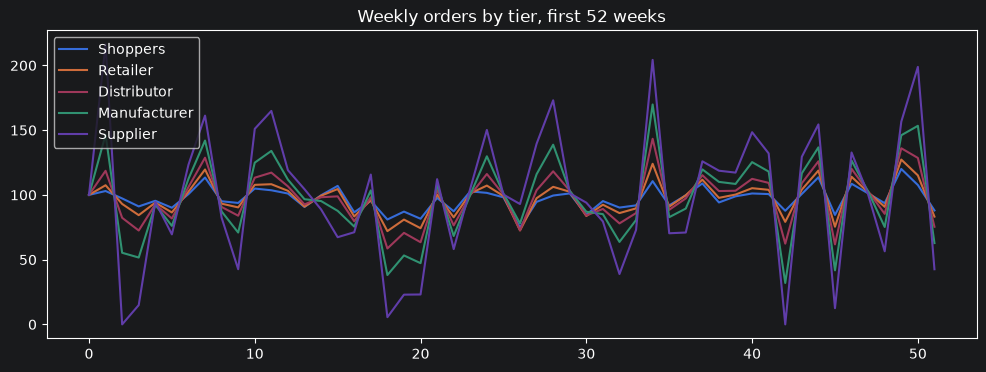

In [16]:
plt.figure(figsize=(12, 4))
for name, o in zip(names, orders):
    plt.plot(o[:52], label=name)
plt.legend(); plt.title("Weekly orders by tier, first 52 weeks"); plt.show()

In [21]:
def ratios(orders):
    d = orders[0]
    return [round(o.var() / d.var(), 1) for o in orders[1:]]

In [20]:
atta = pd.read_csv("kalpa_atta_pos.csv")
demand = atta.bags_sold.to_numpy().astype(float)
print(atta.head())
print(atta.columns)

         week  bags_sold
0  2024-11-04       1184
1  2024-11-11       1218
2  2024-11-18       1239
3  2024-11-25       1182
4  2024-12-02       1259
Index(['week', 'bags_sold'], dtype='str')


In [23]:

# TODO 1: print ratios(simulate(demand, lead=3, window=6))
demand = atta["bags_sold"].to_numpy()

orders = simulate(
    demand,
    lead=3,
    window=6,
    share_pos=False
)

ratios(orders)

[np.float64(2.8), np.float64(10.1), np.float64(38.2), np.float64(123.8)]

In [ ]:
# TODO 2 and 3: run each fix, build a table of variance ratios, sort by Supplier


def calculate_ratios(orders, demand):

    demand_var = np.var(demand)

    names = [
        "Shoppers",
        "Retailer",
        "Distributor",
        "Manufacturer",
        "Supplier"
    ]

    return {
        name: np.var(order) / demand_var
        for name, order in zip(names, orders)
    }

baseline = simulate(
    demand,
    lead=3,
    window=6
)

# 5. Three individual fixes
shared = simulate(
    demand,
    lead=3,
    window=6,
    share_pos=True
)

short_lead = simulate(
    demand,
    lead=1,
    window=6
)

long_forecast = simulate(
    demand,
    lead=3,
    window=12
)

# 6. All fixes together
all_fixes = simulate(
    demand,
    lead=1,
    window=12,
    share_pos=True
)



---
## Task 4: The Kalpa Logistics flyover (10 marks)

1,200 riders go from the Hub to the Market every evening.

- Hub to A: riders on that road divided by 40, in minutes. A to Market: 30 minutes, always.
- Hub to B: 30 minutes, always. B to Market: riders on that road divided by 40.
- The city opens a free flyover from A to B: 0 minutes.

1. Travel time per rider before the flyover, with riders split evenly. (2)
2. Run the loop below. It moves riders onto the flyover route 50 at a time. Find where nobody gains by switching. (4)
3. Travel time per rider after the flyover. (2)
4. What fixed delay on the flyover would keep riders off it? (2)

In [ ]:
for k in range(0, 1201, 100):                # riders on Hub-A-B-Market
    a = b = (1200 - k) / 2                     # the rest split evenly
    t_old = (a + k) / 40 + 30                  # Hub-A-Market
    t_new = (a + k) / 40 + (b + k) / 40        # Hub-A-B-Market
    print(k, "on flyover | old route", round(t_old, 1),
          "| flyover route", round(t_new, 1))

---
## Task 5: The Kalpa Connect support desk (10 marks)

190 calls arrive per hour. Average handle time is 6 minutes. Ops wants agents 95 percent busy.

1. The load in Erlangs (calls per minute times handle time). How many agents make 95 percent busy? (1)
2. With that many agents: probability a caller waits, and the average wait in seconds. (2)
3. The fewest agents that answer at least 80 percent of calls within 20 seconds. (3)
4. Two city teams, each taking half the calls with half your answer from step 3, against one pooled team. Compare the average wait. (2)
5. A two-line reply to ops. (2)

Service level within T seconds = 1 - P(wait) x exp(-(agents - load) x T / handle time).

In [ ]:
def erlang_c(agents, load):
    top = load**agents / factorial(agents) * agents / (agents - load)
    bottom = sum(load**k / factorial(k) for k in range(agents)) + top
    return top / bottom

def service_level(agents, load, aht_sec, t_sec=20):
    return 1 - erlang_c(agents, load) * np.exp(-(agents - load) * t_sec / aht_sec)

def mean_wait_sec(agents, load, aht_sec):
    return erlang_c(agents, load) * aht_sec / (agents - load)


In [ ]:
load = 190 / 60 * 6
# TODO 1 and 2: agents for 95% busy, then P(wait) and mean wait in seconds


In [ ]:
# TODO 3: loop over 20 to 28 agents and print busy %, service level and mean wait


In [ ]:
# TODO 4: pooled team of your answer against two teams of half the size, half the load each
